# Scale seasonality based on MAGICC NPP

## Imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import openscm_units
import pandas_indexing as pix
import pandas_openscm
import pandas_openscm.db
import pint_xarray
import seaborn as sns
import tqdm.auto
import xarray as xr

from cmip7_scenariomip_ghg_generation.scenario_info import ScenarioInfo

## Parameters

In [2]:
ghg: str = "co2"
scenario_info_markers: str = (
    "WITCH 6.0;SSP5 - Medium-Low Emissions_a;hl;;"
    "REMIND-MAgPIE 3.5-4.10;SSP1 - Very Low Emissions;vl;;"
    "MESSAGEix-GLOBIOM-GAINS 2.1-M-R12;SSP2 - Low Emissions;l;;"
    "IMAGE 3.4;SSP2 - Medium Emissions;m;;"
    "GCAM 7.1 scenarioMIP;SSP3 - High Emissions;h;;"
    "AIM 3.0;SSP2 - Low Overshoot;ln;;"
    "COFFEE 1.6;SSP2 - Medium-Low Emissions;ml"
)
harmonisation_year: int = 2023
magicc_output_db_dir: str = "../output-bundles/dev-test/data/interim/magicc-output/db"
magicc_db_backend_str: str = "feather"
historical_data_seasonality_lat_gradient_info_root: str = (
    "../output-bundles/dev-test/data/raw/historical-ghg-data-interim"
)
out_file: str = (
    "../output-bundles/dev-test/data/interim/seasonality/modelling-based-projection_co2_seasonality-all-time.nc"
)

In [3]:
# Parameters
ghg = "co2"
scenario_info_markers = "REMIND-MAgPIE 3.5-4.11;VL-cf;vl-cf"
harmonisation_year = 2015
magicc_output_db_dir = "/Users/znicholls/Documents/repos/cmip7-scenariomip-ghg-concentrations/output-bundles/1.1.0/data/interim/magicc-output/db"
magicc_db_backend_str = "feather"
historical_data_seasonality_lat_gradient_info_root = "/Users/znicholls/Documents/repos/cmip7-scenariomip-ghg-concentrations/output-bundles/1.1.0/data/raw/historical-ghg-data-interim"
out_file = "/Users/znicholls/Documents/repos/cmip7-scenariomip-ghg-concentrations/output-bundles/1.1.0/data/interim/seasonality/modelling-based-projection_co2_seasonality-all-time.nc"


## Parse parameters

In [4]:
siml = []
for v in scenario_info_markers.split(";;"):
    model, scenario, cmip_scenario_name = v.split(";")
    siml.append(
        ScenarioInfo(
            cmip_scenario_name=cmip_scenario_name,
            model=model,
            scenario=scenario,
        )
    )

scenario_info_markers_p = tuple(siml)
historical_data_seasonality_lat_gradient_info_root_p = Path(historical_data_seasonality_lat_gradient_info_root)
magicc_output_db = pandas_openscm.db.OpenSCMDB(
    backend_data=pandas_openscm.db.DATA_BACKENDS.get_instance(magicc_db_backend_str),
    backend_index=pandas_openscm.db.INDEX_BACKENDS.get_instance(magicc_db_backend_str),
    db_dir=Path(magicc_output_db_dir),
)
out_file_p = Path(out_file)

## Set up

In [5]:
ur = pint_xarray.setup_registry(openscm_units.unit_registry)
Q = ur.Quantity
pandas_openscm.register_pandas_accessor()

## Load data

### MAGICC NPP

In [6]:
magicc_output_db_reader = magicc_output_db.create_reader()
# magicc_output_db_reader

In [7]:
magiccc_output_l = []
for si in tqdm.auto.tqdm(scenario_info_markers_p):
    magiccc_output_l.append(
        magicc_output_db_reader.load(
            pix.isin(model=si.model, scenario=si.scenario, climate_model="MAGICCv7.6.0a3", variable="CO2_CURRENT_NPP")
            # progress=True,
        ).pix.assign(scenario=si.cmip_scenario_name)
    )

magiccc_output = pix.concat(magiccc_output_l)
magiccc_output_median = magiccc_output.openscm.groupby_except("run_id").median()
# magiccc_output_median.pix.project(["model", "scenario"]).T.plot()
# magiccc_output_median

  0%|          | 0/1 [00:00<?, ?it/s]

In [8]:
# magiccc_output_median.pix.project(["model", "scenario"]).T.plot()

# Take any scenario, doesn't matter as all the same pre-harmonisation
magiccc_output_median_historical = magiccc_output_median.loc[:, :harmonisation_year].iloc[:1, :]
magiccc_output_median_historical

,,,,,,time,1750,1751,1752,1753,1754,1755,1756,1757,1758,1759,...,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015
climate_model,model,region,scenario,unit,variable,run_mode,,,,,,,,,,,,,,,,,,,,,
MAGICCv7.6.0a3,REMIND-MAgPIE 3.5-4.11,World,vl-cf,GtC / yr,CO2_CURRENT_NPP,magicc-concentration-to-emissions-switch,53.2807,53.2807,53.2807,53.2807,53.2807,53.2807,53.2807,53.2807,53.2807,53.2807,...,66.075902,66.196097,66.535337,66.591656,67.033108,67.202738,67.425994,67.812895,67.862659,68.25724


### CMIP7 historical seasonality

In [9]:
def load_file_from_glob(glob: str, base_dir: Path) -> xr.Dataset:
    """
    Load a single file based on a glob pattern
    """
    file_l = list(base_dir.rglob(glob))
    if len(file_l) != 1:
        raise AssertionError(file_l)

    ds = xr.load_dataset(file_l[0])

    return ds

In [10]:
cmip7_seasonality_base = (
    load_file_from_glob(
        f"{ghg}_observational-network_seasonality.nc", historical_data_seasonality_lat_gradient_info_root_p
    )
    .pint.quantify(unit_registry=ur)
    .rename({"__xarray_dataarray_variable__": "seasonality"})
)
cmip7_seasonality_base

Magnitude,[[-0.17158756434653083 -0.42111771661134534 -0.5485749812849801 -0.5084979046040972 -0.36380440277634646 -0.18476945614711068 0.10998678745419231 0.4340148913464566 0.5874921291424312 0.5460088162043599 0.39058590905334223 0.13026333545474245] [-0.35684873773389925 -0.5659023942052439 -0.6035288215924052 -0.4846395565127063 -0.29808805826576057 -0.09289585651213544 0.19623127803299137 0.5192848309965759 0.6610782417174037 0.5941872992050943 0.39187687864670334 0.03924465005627156] [-0.35272174060122946 -0.5166704142294798 -0.523865153572915 -0.37509394456503875 -0.19854462489571645 0.0036113837084586035 0.27025711917005885 0.48091658581573127 0.5313085892364214 0.4464314080419634 0.26703165040956045 -0.032661206734191144] [-0.13088919934957075 -0.19873939597492254 -0.26219616805193774 -0.23865538254924717 -0.18590903152349436 -0.01564970890249401 0.21902997875245117 0.27586389660255434 0.21741134394898287 0.18615294716446468 0.1304028015320529 0.003177565580924323] [0.11728008387633561 0.17018262373008694 0.11207861962593545 0.014633320382999903 -0.06526318694658834 0.03487149915693059 0.15289057830875927 -0.0412048855376714 -0.24203713479970157 -0.20142399941174824 -0.06659281998672219 0.014584535757748209] [0.46965764682437205 0.7798216500455677 0.8095017950613418 0.5735226654807873 0.3208652797921472 0.16976814279289715 -0.12064708148556012 -0.6820827806952702 -1.0468302003411187 -0.819336149874343 -0.41906278535782215 -0.03517937600732366] [0.8586460319482531 1.504154587294341 1.9113554216019017 2.1670750430073706 1.8884347456885373 0.8544237361947254 -0.6346902113352217 -2.2166728383902234 -2.898976519514777 -2.2863301996464176 -1.0995028003583969 -0.04791782230181472] [1.482695427952772 2.147478534590111 2.725764536873225 3.2754356830839964 2.8018069005071324 0.9217539390240277 -1.6307009602650657 -3.9331350137449115 -4.410138437790484 -2.9009294199520355 -0.9531090780897962 0.4730771758017129] [2.6601524733826643 3.1972853800155114 3.7089184728815225 3.948490762532584 2.7724344728344756 -0.37743687784718716 -4.181385444718427 -6.4631978381205535 -5.360270074605418 -2.134973005197628 0.3798295062374643 1.8501514475660044] [4.128378674448143 4.541715259409676 4.813338270950534 4.579218660662789 3.1301715406377713 -0.4878658523103248 -6.015417044229732 -9.476796343543434 -7.425587221922878 -2.3858695454805985 1.373478813947955 3.2252334396027664] [4.039058930645094 4.599681880809443 5.029569607979166 5.117367090495011 4.429021047253433 1.1865796188938773 -5.492773291759542 -10.275239846324318 -8.600840208530464 -3.570888856668455 0.5807897508862657 2.957673802263842] [4.042912594537712 4.594296997339329 5.028142093959126 5.191750406389506 4.916094913553573 2.346675811862199 -4.383412145137967 -10.256498178459395 -9.511854667151928 -4.632316989623158 -0.08791412357040536 2.752123203761606]]
Units,ppm


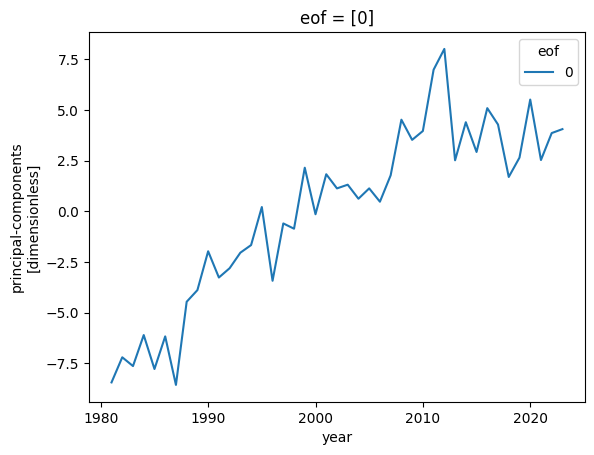

In [11]:
cmip7_seasonality_pieces_ds = load_file_from_glob(
    f"{ghg}_observational-network_seasonality-change-eofs.nc", historical_data_seasonality_lat_gradient_info_root_p
).pint.quantify(unit_registry=ur)
cmip7_seasonality_pieces_ds["principal-components"].plot(hue="eof")
# cmip7_seasonality_pieces_ds

## Scale seasonality pc

In [12]:
if cmip7_seasonality_pieces_ds["eof"].size != 1:
    raise AssertionError

pc0 = cmip7_seasonality_pieces_ds["principal-components"].sel(eof=0)
# pc0

In [13]:
regression_years = np.intersect1d(
    pc0["year"],
    magiccc_output_median_historical.columns,
)
regression_years

array([1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991,
       1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002,
       2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013,
       2014, 2015])

In [14]:
pc0_to_regress = pc0.sel(year=regression_years)
# pc0_to_regress

In [15]:
magiccc_output_median_historical_u_l = magiccc_output_median_historical.pix.unique("unit")
if len(magiccc_output_median_historical_u_l) != 1:
    raise AssertionError(magiccc_output_median_historical_u_l)

magiccc_output_median_historical_u = magiccc_output_median_historical_u_l[0]
# magiccc_output_median_historical_u

In [16]:
magiccc_output_median_historical_to_regress_q = Q(
    magiccc_output_median_historical.loc[:, regression_years].values.squeeze(),
    magiccc_output_median_historical_u,
)
# magiccc_output_median_historical_to_regress_q

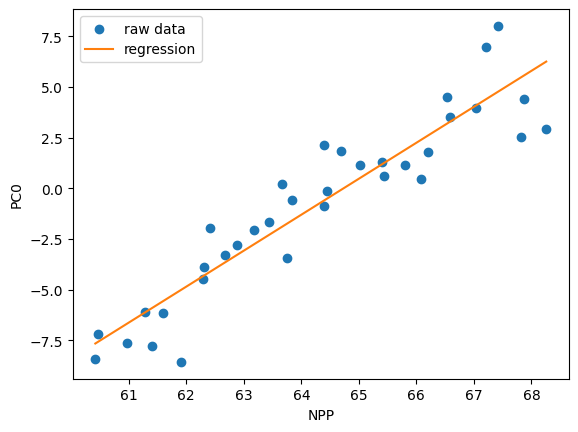

In [17]:
x = magiccc_output_median_historical_to_regress_q
A = np.vstack([x.m, np.ones(x.size)]).T
y = pc0_to_regress.data

res = np.linalg.lstsq(A, y.m, rcond=None)
m, c = res[0]
m = Q(m, (y / x).units)
# c = Q(c, y.units)

fig, ax = plt.subplots()
ax.scatter(x.m, y.m, label="raw data")
ax.plot(x.m, (m * x + c).m, color="tab:orange", label="regression")
ax.set_ylabel("PC0")
ax.set_xlabel("NPP")
ax.legend()

## Scale PC

In [18]:
last_hist_year = int(cmip7_seasonality_pieces_ds["year"].max().values)
# last_hist_year

In [19]:
delta_npp = (
    magiccc_output_median.loc[:, last_hist_year:].subtract(magiccc_output_median[last_hist_year], axis="rows")
).pix.assign(variable="change_in_npp")
# delta_npp

In [20]:
delta_npp_unit_l = delta_npp.pix.unique("unit")
if len(delta_npp_unit_l) != 1:
    raise AssertionError(delta_npp_unit_l)

delta_npp_unit = delta_npp_unit_l[0]

delta_npp_xr = xr.DataArray(
    delta_npp.values,
    dims=["scenario", "year"],
    coords=dict(scenario=delta_npp.index.get_level_values("scenario"), year=delta_npp.columns.values),
).pint.quantify(delta_npp_unit, unit_registry=ur)
# delta_npp_xr

In [21]:
delta_pc = delta_npp_xr * m
# delta_pc

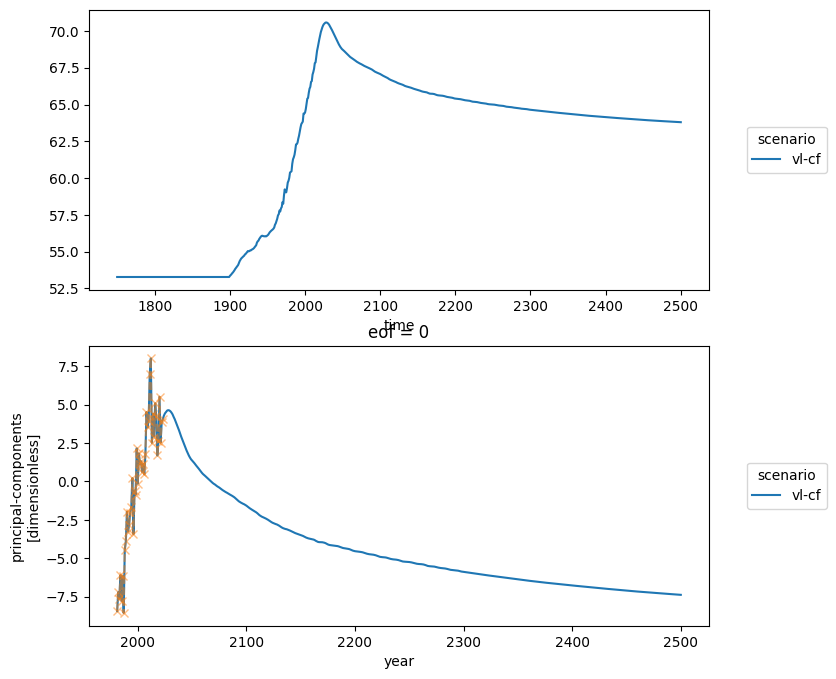

In [22]:
pc0_extended = delta_pc + pc0.sel(year=last_hist_year).data
pc0_extended = xr.concat(
    [
        pc0.sel(year=pc0["year"] < pc0_extended["year"].min()),
        pc0_extended,
    ],
    dim="year",
)

fig, axes = plt.subplots(nrows=2, figsize=(8, 8))
magiccc_output_median.pix.project("scenario").T.plot(ax=axes[0])
pc0_extended.pint.to("dimensionless").plot(ax=axes[1], hue="scenario")
pc0.pint.to("dimensionless").plot(ax=axes[1], linestyle="--", alpha=0.5, marker="x")
for ax in axes:
    sns.move_legend(ax, loc="center left", bbox_to_anchor=(1.05, 0.5))

## Prepare output

In [23]:
out_seasonality_delta = (cmip7_seasonality_pieces_ds["eofs"] * pc0_extended).sum("eof")
out = out_seasonality_delta + cmip7_seasonality_base["seasonality"]
out = out.pint.dequantify()
# out

## Save

In [24]:
out_file_p.parent.mkdir(exist_ok=True, parents=True)
out.to_netcdf(out_file_p)
out_file_p

PosixPath('/Users/znicholls/Documents/repos/cmip7-scenariomip-ghg-concentrations/output-bundles/1.1.0/data/interim/seasonality/modelling-based-projection_co2_seasonality-all-time.nc')